# Clustering 2025 NFL wide receivers into role archetypes

INST 414 Module 3. Data: nflverse 2025 regular season (built by `src/build_features.py`).
Method: standardize 9 usage/style features, K-Means with Euclidean distance, pick k with elbow + silhouette + seed stability.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

# find the repo root (folder that has data/) so the notebook runs from anywhere in the repo
root = Path.cwd()
while not (root / "data" / "wr_features_2025.csv").exists():
    root = root.parent
FIG = root / "article" / "figures"
RES = root / "results"
FIG.mkdir(parents=True, exist_ok=True)
RES.mkdir(exist_ok=True)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## Load data and apply the volume filter (50+ targets)

In [2]:
all_wr = pd.read_csv(root / "data" / "wr_features_2025.csv")
df = all_wr[all_wr["meets_threshold"]].reset_index(drop=True)

features = ["targets_per_game", "target_share", "air_yards_share", "adot", "yac_per_rec",
            "catch_rate", "deep_rate", "behind_los_rate", "rz_target_rate"]

print("WRs with 1+ target:", len(all_wr))
print("WRs with 50+ targets:", len(df))
print("smallest target count kept:", df["targets"].min())
print("missing values in features:", df[features].isna().sum().sum())
df[features].describe().T.round(3)

WRs with 1+ target: 223
WRs with 50+ targets: 78
smallest target count kept: 51
missing values in features: 0


,count,mean,std,min,25%,50%,75%,max
targets_per_game,78.0,6.149,1.893,3.118,4.643,6.000,7.265,11.562
target_share,78.0,0.200,0.062,0.098,0.154,0.191,0.234,0.358
air_yards_share,78.0,0.275,0.101,0.102,0.186,0.281,0.356,0.500
adot,78.0,10.874,2.758,3.674,8.677,11.295,12.663,18.964
yac_per_rec,78.0,4.062,1.397,1.233,3.000,3.852,4.870,7.811
catch_rate,78.0,0.624,0.079,0.444,0.577,0.624,0.678,0.833
deep_rate,78.0,0.169,0.065,0.047,0.118,0.177,0.211,0.327
behind_los_rate,78.0,0.106,0.099,0.000,0.035,0.072,0.141,0.400
rz_target_rate,78.0,0.128,0.044,0.036,0.099,0.126,0.149,0.281


## Standardize

In [3]:
scaler = StandardScaler()
X = scaler.fit_transform(df[features])
print(X.shape)
print("means ~0:", np.round(X.mean(axis=0), 6))
print("std ~1:", np.round(X.std(axis=0), 6))

(78, 9)
means ~0: [-0. -0.  0. -0.  0.  0.  0.  0.  0.]
std ~1: [1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Choosing k: elbow (inertia), silhouette, and stability across seeds for k = 2..15

In [4]:
rows = []
for k in range(2, 16):
    km = KMeans(n_clusters=k, n_init=50, random_state=414).fit(X)
    sil = silhouette_score(X, km.labels_)
    # stability: rerun with 20 different seeds (10 random starts each) and compare to the first
    runs = [KMeans(n_clusters=k, n_init=10, random_state=s).fit(X).labels_ for s in range(20)]
    ari = np.mean([adjusted_rand_score(runs[0], r) for r in runs[1:]])
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": sil, "mean_ari_vs_seed0": ari,
                 "smallest_cluster": np.bincount(km.labels_).min()})
ksel = pd.DataFrame(rows)
ksel.to_csv(RES / "k_selection.csv", index=False)
ksel.round(3)

,k,inertia,silhouette,mean_ari_vs_seed0,smallest_cluster
0,2,520.028,0.259,0.948,24
1,3,412.518,0.215,0.969,20
2,4,351.961,0.213,0.759,7
3,5,318.419,0.188,0.691,7
4,6,290.964,0.179,0.620,6
5,7,261.849,0.192,0.637,6
6,8,244.527,0.192,0.664,6
7,9,220.940,0.204,0.723,2
8,10,208.767,0.202,0.643,3
9,11,196.276,0.197,0.654,2


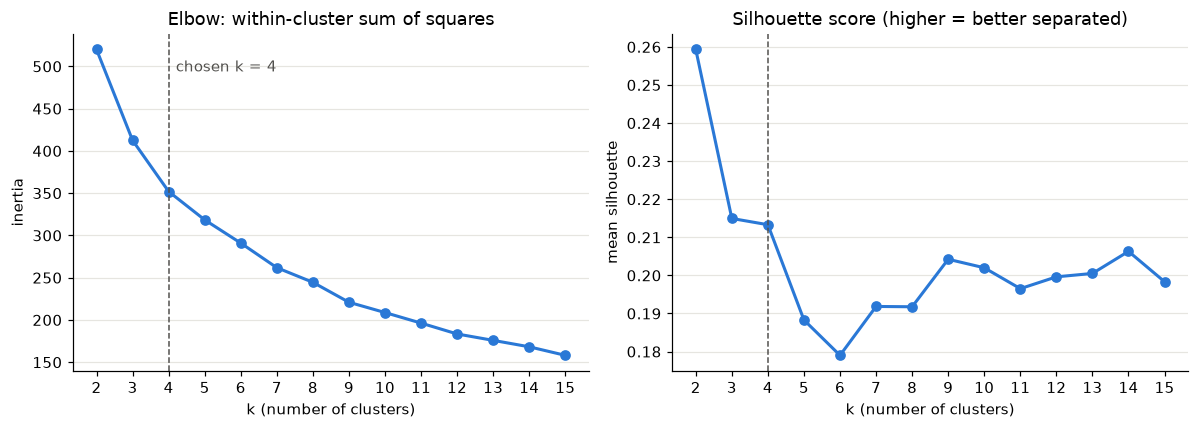

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ksel["k"], ksel["inertia"], marker="o", color="#2a78d6", lw=2, ms=6)
ax[0].set_title("Elbow: within-cluster sum of squares")
ax[0].set_xlabel("k (number of clusters)")
ax[0].set_ylabel("inertia")
ax[1].plot(ksel["k"], ksel["silhouette"], marker="o", color="#2a78d6", lw=2, ms=6)
ax[1].set_title("Silhouette score (higher = better separated)")
ax[1].set_xlabel("k (number of clusters)")
ax[1].set_ylabel("mean silhouette")
for a in ax:
    a.axvline(4, color="#52514e", ls="--", lw=1)
    a.set_xticks(range(2, 16))
    a.grid(axis="y", color="#e6e5e0", lw=0.8)
ax[0].text(4.2, ksel["inertia"].max() * 0.95, "chosen k = 4", color="#52514e")
fig.tight_layout()
fig.savefig(FIG / "elbow_silhouette.png", bbox_inches="tight")
plt.show()

k = 4. k = 2 has the best silhouette but it only splits high-volume receivers from everyone else. The inertia drop
from 3 to 4 is still big, after 4 the curve flattens out, and silhouette is basically the same at 3 and 4 and then falls at 5.
k = 4 also pulls out a small behind-the-line / YAC group that k = 3 merges into the others.
k = 3 is more stable across seeds, so stability for k = 4 is checked in more detail at the end.

## Fit the final model (k = 4)

In [6]:
K = 4
# lots of random starts because several k=4 solutions have almost the same inertia (see stability section)
km = KMeans(n_clusters=K, n_init=500, random_state=414).fit(X)
print("final inertia:", round(km.inertia_, 2))
print("final silhouette:", round(silhouette_score(X, km.labels_), 4))
df["cluster_id"] = km.labels_

z = pd.DataFrame(X, columns=features)
z["cluster_id"] = km.labels_
zmean = z.groupby("cluster_id")[features].mean()

# name clusters by looking at their profiles (rules written after looking at the means)
names = {}
left = list(range(K))
c = zmean.loc[left, "behind_los_rate"].idxmax(); names[c] = "Screen & YAC weapons"; left.remove(c)
c = zmean.loc[left, "target_share"].idxmax(); names[c] = "Target hogs"; left.remove(c)
c = zmean.loc[left, "adot"].idxmax(); names[c] = "Field stretchers"; left.remove(c)
names[left[0]] = "Secondary options"
order = ["Target hogs", "Field stretchers", "Secondary options", "Screen & YAC weapons"]
colors = {"Target hogs": "#2a78d6", "Field stretchers": "#eda100",
          "Secondary options": "#e34948", "Screen & YAC weapons": "#1baf7a"}
markers = {"Target hogs": "o", "Field stretchers": "^", "Secondary options": "s", "Screen & YAC weapons": "D"}
df["cluster"] = df["cluster_id"].map(names)
df["cluster"].value_counts()[order]

final inertia: 351.59
final silhouette: 0.2118


cluster
Target hogs             17
Field stretchers        27
Secondary options       27
Screen & YAC weapons     7
Name: count, dtype: int64

## Cluster profiles (raw means and standardized means)

In [7]:
outcomes = ["yards_per_target", "epa_per_target", "td_per_target", "ppr_per_game"]
profile = df.groupby("cluster")[features + outcomes].mean().loc[order]
profile.insert(0, "n_players", df["cluster"].value_counts()[order])
profile.to_csv(RES / "cluster_profiles.csv")
profile.round(3).T

cluster,Target hogs,Field stretchers,Secondary options,Screen & YAC weapons
n_players,17.000,27.000,27.000,7.000
targets_per_game,8.629,6.123,4.819,5.350
target_share,0.286,0.194,0.157,0.179
air_yards_share,0.381,0.326,0.193,0.130
adot,10.576,13.451,9.689,6.236
yac_per_rec,4.449,3.539,3.718,6.461
catch_rate,0.654,0.566,0.639,0.719
deep_rate,0.156,0.232,0.130,0.112
behind_los_rate,0.102,0.063,0.086,0.360
rz_target_rate,0.121,0.130,0.128,0.139


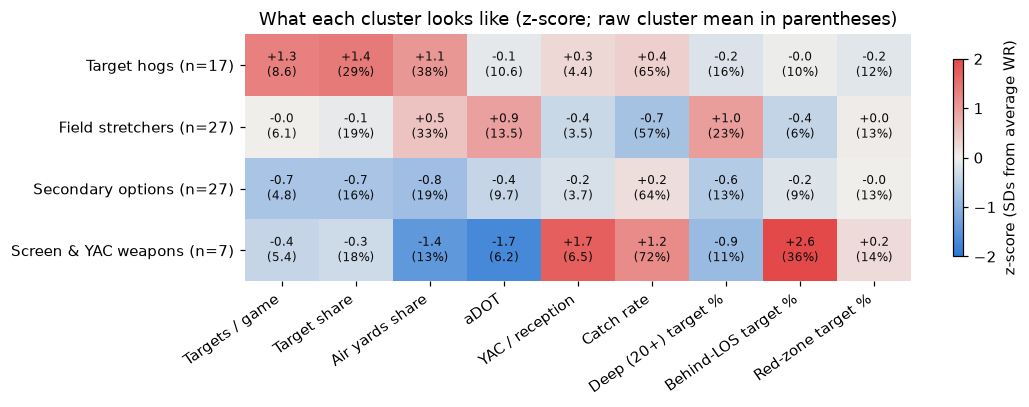

In [8]:
zprof = z.assign(cluster=df["cluster"]).groupby("cluster")[features].mean().loc[order]
zprof.to_csv(RES / "cluster_profiles_z.csv")
labels = {"targets_per_game": "Targets / game", "target_share": "Target share", "air_yards_share": "Air yards share",
          "adot": "aDOT", "yac_per_rec": "YAC / reception", "catch_rate": "Catch rate",
          "deep_rate": "Deep (20+) target %", "behind_los_rate": "Behind-LOS target %", "rz_target_rate": "Red-zone target %"}
cmap = LinearSegmentedColormap.from_list("bgr", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(10, 3.8))
im = ax.imshow(zprof.values, cmap=cmap, vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(features)))
ax.set_xticklabels([labels[f] for f in features], rotation=35, ha="right")
ax.set_yticks(range(K))
ax.set_yticklabels([f"{c} (n={(df['cluster'] == c).sum()})" for c in order])
for i in range(K):
    for j in range(len(features)):
        raw = profile.iloc[i][features[j]]
        txt = f"{raw:.0%}" if features[j] not in ["targets_per_game", "adot", "yac_per_rec"] else f"{raw:.1f}"
        ax.text(j, i, f"{zprof.iloc[i, j]:+.1f}\n({txt})", ha="center", va="center", fontsize=8, color="#0b0b0b")
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8)
cb.set_label("z-score (SDs from average WR)")
ax.set_title("What each cluster looks like (z-score; raw cluster mean in parentheses)")
fig.tight_layout()
fig.savefig(FIG / "cluster_profiles_heatmap.png", bbox_inches="tight")
plt.show()

## Example players per cluster (closest to the cluster center = most typical)

In [9]:
dist = km.transform(X)
df["dist_to_center"] = [dist[i, df.loc[i, "cluster_id"]] for i in range(len(df))]
examples = {}
for c in order:
    sub = df[df["cluster"] == c].sort_values("dist_to_center")
    examples[c] = {
        "most_typical": list(sub["player"].head(4)),
        "most_targeted": list(sub.sort_values("targets", ascending=False)["player"].head(4)),
    }
    print(c, "| typical:", examples[c]["most_typical"], "| most targeted:", examples[c]["most_targeted"])

cols = ["player", "team", "cluster", "games", "targets", "receptions", "receiving_yards", "receiving_tds",
        "dist_to_center"] + features + outcomes
df[cols].sort_values(["cluster", "dist_to_center"]).to_csv(RES / "cluster_assignments.csv", index=False)

Target hogs | typical: ['CeeDee Lamb', 'A.J. Brown', 'Drake London', 'Justin Jefferson'] | most targeted: ["Ja'Marr Chase", 'Amon-Ra St. Brown', 'Puka Nacua', 'Jaxon Smith-Njigba']
Field stretchers | typical: ['Marvin Harrison Jr.', 'Tee Higgins', 'Jordan Addison', 'Parker Washington'] | most targeted: ['Emeka Egbuka', 'Michael Wilson', 'Courtland Sutton', 'Davante Adams']
Secondary options | typical: ['Marquise Brown', 'Xavier Hutchinson', 'Ladd McConkey', 'Andrei Iosivas'] | most targeted: ['Keenan Allen', 'Michael Pittman', 'Jakobi Meyers', 'Ladd McConkey']
Screen & YAC weapons | typical: ['Deebo Samuel Sr.', 'Malik Washington', 'Khalil Shakir', 'Chimere Dike'] | most targeted: ['Deebo Samuel Sr.', 'Khalil Shakir', 'Rashee Rice', 'Chimere Dike']


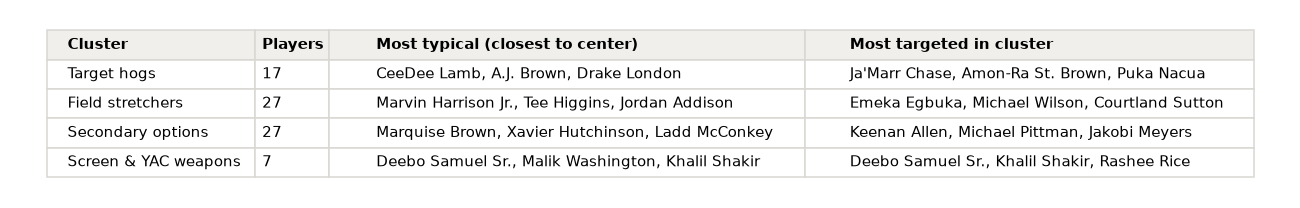

In [10]:
# table figure: sizes and examples (Medium has no tables, so this goes in as an image)
tbl = []
for c in order:
    sub = df[df["cluster"] == c]
    tbl.append([c, str(len(sub)), ", ".join(examples[c]["most_typical"][:3]), ", ".join(examples[c]["most_targeted"][:3])])
fig, ax = plt.subplots(figsize=(15, 2.2))
ax.axis("off")
t = ax.table(cellText=tbl, colLabels=["Cluster", "Players", "Most typical (closest to center)", "Most targeted in cluster"],
             loc="center", cellLoc="left", colLoc="left", colWidths=[0.17, 0.07, 0.38, 0.38])
t.auto_set_column_width(col=[0, 1, 2, 3])
t.auto_set_font_size(False)
t.set_fontsize(9.5)
t.scale(1, 1.6)
for (r, cc), cell in t.get_celld().items():
    cell.set_edgecolor("#d8d7d2")
    if r == 0:
        cell.set_text_props(weight="bold")
        cell.set_facecolor("#f0efec")
fig.savefig(FIG / "cluster_table.png", bbox_inches="tight", dpi=160)
plt.show()

## 2D view with PCA

In [11]:
pca = PCA(n_components=2, random_state=414)
P = pca.fit_transform(X)
df["pc1"], df["pc2"] = P[:, 0], P[:, 1]
print("variance explained:", np.round(pca.explained_variance_ratio_, 3), "total", round(pca.explained_variance_ratio_.sum(), 3))
loadings = pd.DataFrame(pca.components_.T, index=features, columns=["PC1", "PC2"])
loadings.round(2)

variance explained: [0.389 0.278] total 0.666


,PC1,PC2
targets_per_game,0.10,0.60
target_share,0.09,0.61
air_yards_share,0.39,0.39
adot,0.49,-0.11
yac_per_rec,-0.35,0.17
catch_rate,-0.35,0.18
deep_rate,0.41,-0.12
behind_los_rate,-0.41,0.08
rz_target_rate,-0.06,0.12


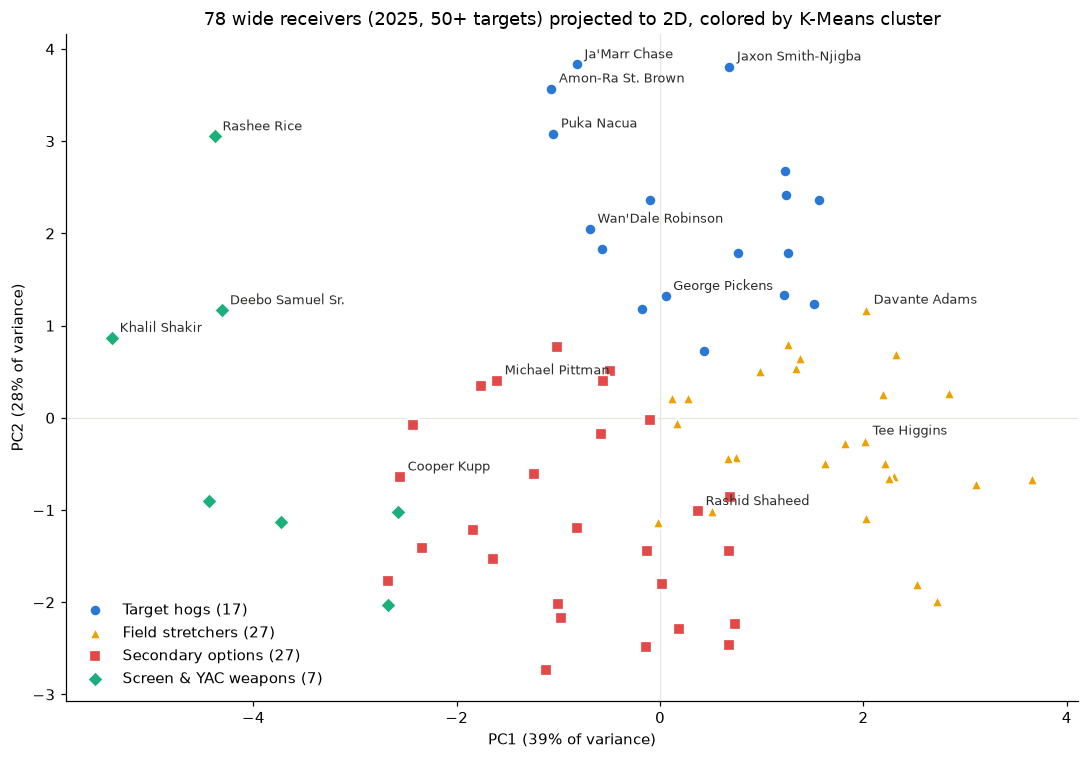

In [12]:
label_these = ["Ja'Marr Chase", "Puka Nacua", "Jaxon Smith-Njigba", "Amon-Ra St. Brown",
               "Deebo Samuel Sr.", "Rashee Rice", "Khalil Shakir", "Davante Adams", "Tee Higgins",
               "Rashid Shaheed", "Michael Pittman", "Cooper Kupp", "Wan'Dale Robinson", "George Pickens"]
fig, ax = plt.subplots(figsize=(10, 7))
for c in order:
    sub = df[df["cluster"] == c]
    ax.scatter(sub["pc1"], sub["pc2"], s=60, color=colors[c], marker=markers[c], label=f"{c} ({len(sub)})",
               edgecolor="white", linewidth=1.5, zorder=3)
for _, r in df[df["player"].isin(label_these)].iterrows():
    ax.annotate(r["player"], (r["pc1"], r["pc2"]), xytext=(5, 4), textcoords="offset points", fontsize=8.5, color="#2b2b2a")
ax.axhline(0, color="#e6e5e0", lw=0.8, zorder=1)
ax.axvline(0, color="#e6e5e0", lw=0.8, zorder=1)
ev = pca.explained_variance_ratio_
ax.set_xlabel(f"PC1 ({ev[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({ev[1]:.0%} of variance)")
ax.set_title("78 wide receivers (2025, 50+ targets) projected to 2D, colored by K-Means cluster")
ax.legend(frameon=False, loc="best")
fig.tight_layout()
fig.savefig(FIG / "pca_clusters.png", bbox_inches="tight")
plt.show()

## After clustering: how productive is each role per target? (outcomes were NOT used to cluster)

In [13]:
# pooled per-target numbers (total EPA / total targets) so high-volume players count more
pooled = df.groupby("cluster")[["targets", "receiving_epa", "receiving_yards", "receiving_tds"]].sum().loc[order]
pooled["epa_per_target"] = pooled["receiving_epa"] / pooled["targets"]
pooled["yards_per_target"] = pooled["receiving_yards"] / pooled["targets"]
pooled["td_per_100_targets"] = 100 * pooled["receiving_tds"] / pooled["targets"]
spread = df.groupby("cluster")["epa_per_target"].agg(["median", "min", "max", "std"]).loc[order]
pooled.join(spread, rsuffix="_player").round(3)

,targets,receiving_epa,receiving_yards,receiving_tds,epa_per_target,yards_per_target,td_per_100_targets,median,min,max,std
cluster,,,,,,,,,,,
Target hogs,2241,717.038,19569,112,0.320,8.732,4.998,0.278,-0.098,0.697,0.211
Field stretchers,2368,557.275,19081,133,0.235,8.058,5.617,0.237,-0.305,0.664,0.234
Secondary options,1973,319.505,14441,90,0.162,7.319,4.562,0.201,-0.407,0.690,0.225
Screen & YAC weapons,522,66.449,3731,24,0.127,7.148,4.598,0.079,-0.151,0.501,0.201


In [14]:
# best and worst EPA per target inside each cluster (same role, different results)
for c in order:
    sub = df[df["cluster"] == c].sort_values("epa_per_target", ascending=False)
    print(c)
    print("  top:", [(p, round(e, 2)) for p, e in zip(sub["player"].head(3), sub["epa_per_target"].head(3))])
    print("  bottom:", [(p, round(e, 2)) for p, e in zip(sub["player"].tail(3), sub["epa_per_target"].tail(3))])

Target hogs
  top: [('Puka Nacua', 0.7), ('George Pickens', 0.65), ('Jaxon Smith-Njigba', 0.56)]
  bottom: [("Wan'Dale Robinson", 0.14), ('Garrett Wilson', -0.04), ('Justin Jefferson', -0.1)]
Field stretchers
  top: [('Alec Pierce', 0.66), ('Christian Watson', 0.59), ('Jameson Williams', 0.55)]
  bottom: [('Elic Ayomanor', -0.11), ('Adonai Mitchell', -0.22), ('Jerry Jeudy', -0.3)]
Secondary options
  top: [('Stefon Diggs', 0.69), ('Ryan Flournoy', 0.51), ('Mack Hollins', 0.42)]
  bottom: [('Calvin Austin III', -0.08), ('Tyler Lockett', -0.16), ('Christian Kirk', -0.41)]
Screen & YAC weapons
  top: [('Luther Burden III', 0.5), ('Rashee Rice', 0.21), ('Deebo Samuel Sr.', 0.18)]
  bottom: [('Marvin Mims Jr.', 0.07), ('Chimere Dike', 0.02), ('Malik Washington', -0.15)]


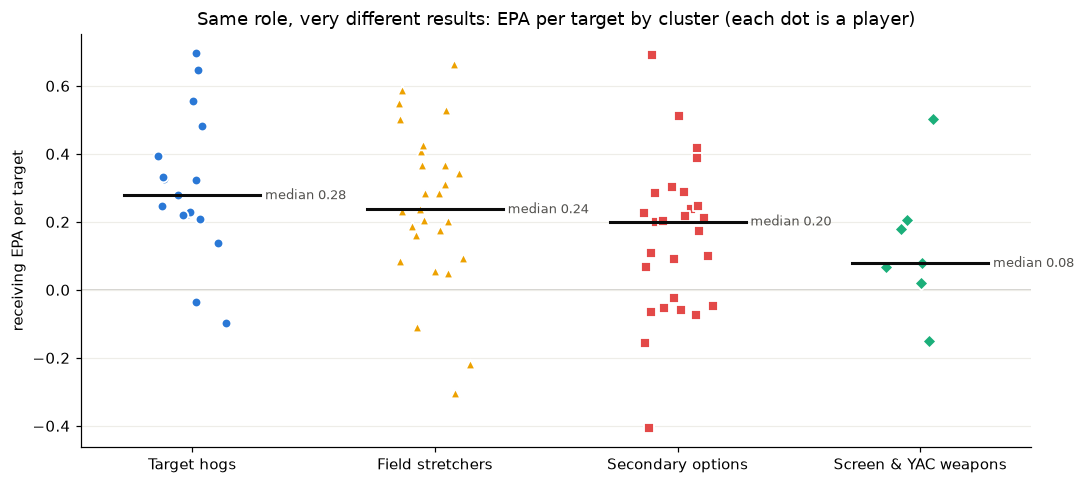

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.5))
rng = np.random.default_rng(414)
for i, c in enumerate(order):
    sub = df[df["cluster"] == c]
    x = i + rng.uniform(-0.15, 0.15, len(sub))
    ax.scatter(x, sub["epa_per_target"], s=40, color=colors[c], marker=markers[c], edgecolor="white", linewidth=1.2, zorder=3)
    med = sub["epa_per_target"].median()
    ax.plot([i - 0.28, i + 0.28], [med, med], color="#0b0b0b", lw=2, zorder=4)
    ax.text(i + 0.3, med, f"median {med:.2f}", va="center", fontsize=8.5, color="#52514e")
ax.axhline(0, color="#c9c8c2", lw=1, zorder=1)
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order)
ax.set_ylabel("receiving EPA per target")
ax.set_title("Same role, very different results: EPA per target by cluster (each dot is a player)")
ax.grid(axis="y", color="#eeede8", lw=0.8)
fig.tight_layout()
fig.savefig(FIG / "epa_by_cluster.png", bbox_inches="tight")
plt.show()

## Stability check for the final k: 30 more seeds (50 random starts each)

In [16]:
from scipy.optimize import linear_sum_assignment

runs = [KMeans(n_clusters=K, n_init=50, random_state=s).fit(X) for s in range(1000, 1030)]
aris_multi = [adjusted_rand_score(km.labels_, r.labels_) for r in runs]
inertias = [r.inertia_ for r in runs]
print("ARI vs final model: mean %.3f, min %.3f, identical in %d/30" % (np.mean(aris_multi), np.min(aris_multi), sum(a > 0.9999 for a in aris_multi)))
print("inertia of the 30 runs: %.2f to %.2f (final model %.2f)" % (min(inertias), max(inertias), km.inertia_))

# match each run's cluster numbers to the final clusters, then count how often each player keeps its cluster
agree = np.zeros(len(df))
for r in runs:
    ct = pd.crosstab(km.labels_, r.labels_).reindex(index=range(K), columns=range(K), fill_value=0).values
    rows_, cols_ = linear_sum_assignment(-ct)
    mapping = {c: rr for rr, c in zip(rows_, cols_)}
    agree += np.array([mapping[l] for l in r.labels_]) == km.labels_
df["same_cluster_share"] = agree / len(runs)
print("players in the same cluster in all 30 runs:", (df["same_cluster_share"] == 1).sum(), "of", len(df))
print(df.groupby("cluster")["same_cluster_share"].apply(lambda s: (s == 1).mean()).loc[order].round(2))
boundary = df[df["same_cluster_share"] < 1].sort_values("same_cluster_share")[["player", "cluster", "same_cluster_share"]]
df[["player", "team", "cluster", "same_cluster_share"]].to_csv(RES / "membership_stability.csv", index=False)
boundary

ARI vs final model: mean 0.820, min 0.707, identical in 5/30
inertia of the 30 runs: 351.59 to 352.13 (final model 351.59)
players in the same cluster in all 30 runs: 67 of 78
cluster
Target hogs             0.88
Field stretchers        0.96
Secondary options       0.70
Screen & YAC weapons    1.00
Name: same_cluster_share, dtype: float64


,player,cluster,same_cluster_share
34,Tre Tucker,Secondary options,0.366667
33,Rashid Shaheed,Secondary options,0.366667
55,Mack Hollins,Secondary options,0.366667
53,Jayden Higgins,Secondary options,0.366667
63,Keon Coleman,Secondary options,0.366667
69,Calvin Austin III,Secondary options,0.366667
74,Van Jefferson,Secondary options,0.366667
14,Nico Collins,Target hogs,0.866667
11,Tetairoa McMillan,Target hogs,0.866667
41,Romeo Doubs,Field stretchers,0.933333


In [17]:
# single random start per seed, for comparison (this is what you get without n_init)
seed_labels = [KMeans(n_clusters=K, n_init=1, random_state=s).fit(X).labels_ for s in range(30)]
aris_single = [adjusted_rand_score(km.labels_, l) for l in seed_labels]
print("single start: mean ARI %.3f, min %.3f" % (np.mean(aris_single), np.min(aris_single)))

# does Agglomerative (Ward) find the same groups?
from sklearn.cluster import AgglomerativeClustering
agg = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X)
ari_ward = adjusted_rand_score(km.labels_, agg.labels_)
print("ARI K-Means vs Ward agglomerative:", round(ari_ward, 3))

single start: mean ARI 0.616, min 0.261
ARI K-Means vs Ward agglomerative: 0.633


In [18]:
summary = {
    "n_wr_any_target": int(len(all_wr)),
    "n_wr_clustered": int(len(df)),
    "min_targets": 50,
    "features": features,
    "k": K,
    "final_silhouette": round(float(silhouette_score(X, km.labels_)), 4),
    "silhouette_k": {int(r.k): round(float(r.silhouette), 4) for r in ksel.itertuples()},
    "inertia_k": {int(r.k): round(float(r.inertia), 2) for r in ksel.itertuples()},
    "seed_ari_k": {int(r.k): round(float(r.mean_ari_vs_seed0), 4) for r in ksel.itertuples()},
    "cluster_sizes": {c: int((df["cluster"] == c).sum()) for c in order},
    "examples": examples,
    "pca_variance_explained": [round(float(v), 4) for v in pca.explained_variance_ratio_],
    "final_model_stability": {"single_start_mean_ari": round(float(np.mean(aris_single)), 4),
                              "single_start_min_ari": round(float(np.min(aris_single)), 4),
                              "final_inertia": round(float(km.inertia_), 2),
                              "rerun_inertia_range": [round(float(min(inertias)), 2), round(float(max(inertias)), 2)],
                              "players_always_same_cluster": int((df["same_cluster_share"] == 1).sum()),
                              "boundary_players": {r.player: round(float(r.same_cluster_share), 2) for r in boundary.itertuples()},
                              "n_init50_mean_ari": round(float(np.mean(aris_multi)), 4),
                              "n_init50_min_ari": round(float(np.min(aris_multi)), 4),
                              "kmeans_vs_ward_ari": round(float(ari_ward), 4)},
    "pooled_epa_per_target": {c: round(float(pooled.loc[c, "epa_per_target"]), 4) for c in order},
    "pooled_yards_per_target": {c: round(float(pooled.loc[c, "yards_per_target"]), 3) for c in order},
}
(RES / "cluster_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("saved results/cluster_summary.json")

saved results/cluster_summary.json
